# 07 - Customer Lifetime Value (CLV) Prediction & Value Tier Classification

---

## 1. Basics & Fundamentals of Customer Lifetime Value (CLV)

### What is Customer Lifetime Value (CLV)?
**Customer Lifetime Value (CLV or LTV)** represents the total revenue or net profit a business can expect to generate from a single customer throughout the entire lifespan of their business relationship.

While **Sales Prediction** forecasts store-level aggregate demand, and **Churn Prediction** flags customers at risk of leaving, **CLV Prediction** evaluates the individual economic potential of each customer. It answers:
- *'How much revenue will this customer generate in the next 3 to 12 months?'*
- *'Which customers belong to our highest value tier (VIP champions) versus low-value one-time buyers?'*
- *'Where should marketing spend its retention and acquisition budget to maximize ROI?'*

---

### Why is CLV Essential for Modern Retail?
1. **LTV to CAC Ratio**: In unit economics, sustainable growth requires CLV / CAC >= 3:1. If acquiring a customer costs $50, their predicted CLV should exceed $150.
2. **Prioritizing Retention vs. Churn**: Not all churning customers have equal impact. Losing a $5,000 High-CLV customer is devastating; losing a $10 one-off buyer is negligible. CLV helps prioritize win-back efforts.
3. **Personalized Marketing**: High-CLV customers get VIP concierge treatment and premium perks, while Low-CLV customers receive automated, cost-effective re-engagement emails.

---

### Mathematical Formulations of CLV

#### 1. Historical CLV (Simple)
The exact historical revenue generated by customer i:
$$\text{CLV}_{\text{hist}} = \sum_{j=1}^{N_i} \text{Order Value}_{i,j} = \text{AOV}_i \times \text{Purchase Count}_i$$

#### 2. Traditional / Deterministic Formula
$$\text{CLV} = \text{Average Order Value (AOV)} \times \text{Purchase Frequency} \times \text{Customer Lifespan}$$
Incorporating profit margin ($m$), retention rate ($r$), and discount rate ($d$):
$$\text{CLV} = m \times \sum_{t=1}^{T} \frac{r^t}{(1 + d)^t} = m \times \left(\frac{r}{1 + d - r}\right)$$

#### 3. Machine Learning Predictive CLV (Supervised Observation & Holdout Framework)
Modern enterprise retail uses machine learning on temporal transaction windows:
1. **Observation Window** ($T_{\text{obs}}$): We extract behavioral signals:
   - **Recency ($R$)**: Days since last transaction up to cutoff.
   - **Frequency ($F$)**: Count of distinct purchase events.
   - **Monetary ($M$)**: Historical total sales in observation window.
   - **Tenure ($T$)**: Days between first purchase and cutoff.
   - **Average Order Value (AOV)**: $M / F$.
   - **Unique Products**: Count of distinct SKUs purchased (product basket breadth).
   - **Average Basket Size**: Average item quantity per invoice.
2. **Future Holdout Window** ($T_{\text{future}}$, next 90 days): We calculate ground-truth target variables:
   - **Continuous Target ($Y_{\text{spend}}$)**: Total dollars spent in the future window (evaluated with **MAE, RMSE, $R^2$**).
   - **Value Tier Target ($Y_{\text{tier}}$)**: Segmenting customers into **High CLV**, **Medium CLV**, and **Low CLV** (evaluated with **Accuracy, F1-Score, Precision, Recall, and Confusion Matrix**).
   - **Binary Top-CLV Target ($Y_{\text{high}}$)**: Predicting top-tier future spenders (evaluated with **Accuracy, F1-Score, ROC-AUC, and Confusion Matrix**).


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
os.makedirs('../models', exist_ok=True)
os.makedirs('../data', exist_ok=True)
print('Libraries imported successfully.')


Libraries imported successfully.


In [2]:
df = pd.read_csv('../data/online_retail_clean.csv')
print('Dataset Shape:', df.shape)
print('Columns:', df.columns.tolist())

col_map = {'Invoice': 'InvoiceNo', 'Customer ID': 'CustomerID', 'Price': 'UnitPrice'}
df = df.rename(columns={k: v for k, v in col_map.items() if k in df.columns})

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df = df.dropna(subset=['CustomerID'])
df['CustomerID'] = df['CustomerID'].astype(int)

if 'TotalPrice' not in df.columns:
    if 'Sales' in df.columns:
        df['TotalPrice'] = df['Sales']
    else:
        df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

df = df[(df['Quantity'] > 0) & (df['TotalPrice'] > 0)]

print(f'Transactions: {len(df):,}')
print(f'Unique Customers: {df["CustomerID"].nunique():,}')
print(f'Date Range: {df["InvoiceDate"].min().strftime("%Y-%m-%d")} to {df["InvoiceDate"].max().strftime("%Y-%m-%d")}')
df.head(3)


Dataset Shape: (400916, 10)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Month', 'Sales']
Transactions: 400,916
Unique Customers: 4,312
Date Range: 2009-12-01 to 2010-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Month,Sales,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-12,83.4,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12,81.0,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-12,81.0,81.0


In [3]:
# Temporal cutoff: Last 3 months as future prediction window
last_date = df['InvoiceDate'].max()
window_end = last_date + pd.Timedelta(days=1)
cutoff = window_end - pd.DateOffset(months=3)

obs = df[df['InvoiceDate'] < cutoff]
future = df[df['InvoiceDate'] >= cutoff]

print(f'Cutoff Date: {cutoff.strftime("%Y-%m-%d")}')
print(f'Observation Window: {obs["InvoiceDate"].min().strftime("%Y-%m-%d")} to {obs["InvoiceDate"].max().strftime("%Y-%m-%d")} ({len(obs):,} transactions)')
print(f'Future Prediction Window: {future["InvoiceDate"].min().strftime("%Y-%m-%d")} to {future["InvoiceDate"].max().strftime("%Y-%m-%d")} ({len(future):,} transactions)')
print(f'Active Customers in Observation: {obs["CustomerID"].nunique():,}')
print(f'Active Customers in Future: {future["CustomerID"].nunique():,}')


Cutoff Date: 2010-09-10
Observation Window: 2009-12-01 to 2010-09-10 (253,543 transactions)
Future Prediction Window: 2010-09-12 to 2010-12-09 (147,373 transactions)
Active Customers in Observation: 3,377
Active Customers in Future: 2,877


In [4]:
# Aggregate observation features
feat = obs.groupby('CustomerID').agg(
    last_purchase=('InvoiceDate', 'max'),
    first_purchase=('InvoiceDate', 'min'),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum'),
    Quantity=('Quantity', 'sum'),
    UniqueProducts=('StockCode', 'nunique'),
).reset_index()

feat['Recency'] = (cutoff - feat['last_purchase']).dt.days
feat['Tenure'] = (cutoff - feat['first_purchase']).dt.days
feat['AvgOrderValue'] = (feat['Monetary'] / feat['Frequency']).round(2)
feat['AvgBasketSize'] = (feat['Quantity'] / feat['Frequency']).round(2)
feat = feat.drop(columns=['last_purchase', 'first_purchase'])

# Calculate actual future monetary spend
future_spend = (
    future.groupby('CustomerID')['TotalPrice']
    .sum()
    .reset_index()
    .rename(columns={'TotalPrice': 'FutureMonetary'})
)

feat = feat.merge(future_spend, on='CustomerID', how='left')
feat['FutureMonetary'] = feat['FutureMonetary'].fillna(0.0).round(2)

# Define 3 Business CLV Value Tiers:
# Low CLV: <= $100
# Medium CLV: $100 < spend < $700
# High CLV: >= $700
def assign_clv_tier(val):
    if val <= 100.0:
        return 'Low CLV'
    elif val < 700.0:
        return 'Medium CLV'
    else:
        return 'High CLV'

feat['CLV_Tier'] = feat['FutureMonetary'].apply(assign_clv_tier)
feat['Is_High_CLV'] = (feat['FutureMonetary'] >= 500.0).astype(int)

print('CLV Tier Distribution:')
print(feat['CLV_Tier'].value_counts())
print('\nTop-Spender (Is_High_CLV) Distribution:')
print(feat['Is_High_CLV'].value_counts(normalize=True).round(3))
feat.head()


CLV Tier Distribution:
CLV_Tier
Low CLV       1483
Medium CLV    1061
High CLV       833
Name: count, dtype: int64

Top-Spender (Is_High_CLV) Distribution:
Is_High_CLV
0    0.675
1    0.325
Name: proportion, dtype: float64


,CustomerID,Frequency,Monetary,Quantity,UniqueProducts,Recency,Tenure,AvgOrderValue,AvgBasketSize,FutureMonetary,CLV_Tier,Is_High_CLV
0,12346,11,372.86,70,26,74,270,33.90,6.36,0.00,Low CLV,0
1,12349,2,1268.52,474,47,115,134,634.26,237.00,1402.62,High CLV,1
2,12355,1,488.21,303,22,112,112,488.21,303.00,0.00,Low CLV,0
3,12358,2,1697.93,590,34,95,276,848.96,295.00,1021.08,High CLV,1
4,12359,5,2012.03,877,82,80,279,402.41,175.40,551.33,Medium CLV,1


## 2. Exploratory Data Analysis (EDA) on CLV Features & Tiers


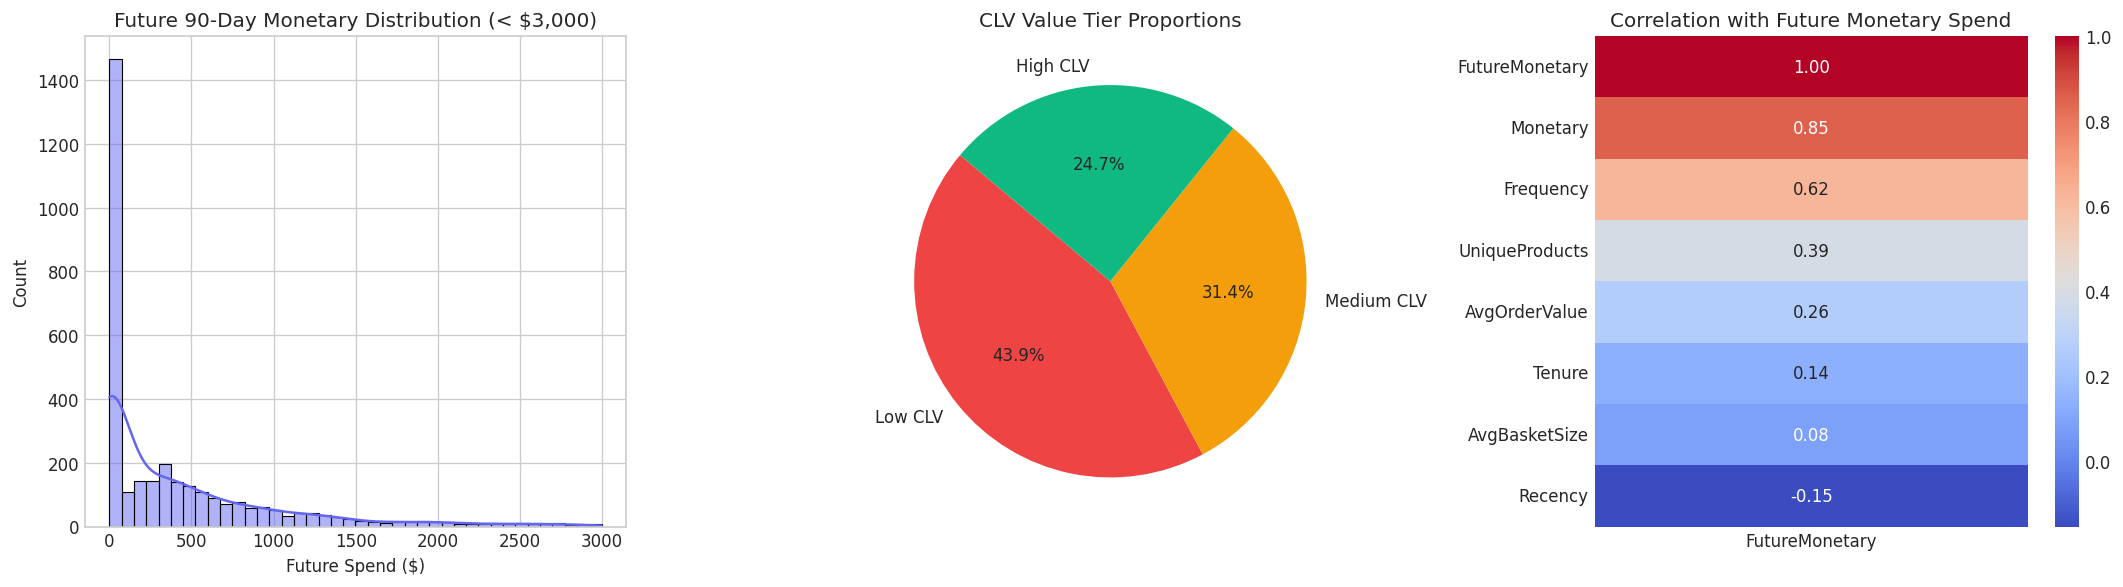

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribution of Future Spend
sns.histplot(feat['FutureMonetary'][feat['FutureMonetary'] < 3000], bins=40, kde=True, ax=axes[0], color='#6366f1')
axes[0].set_title('Future 90-Day Monetary Distribution (< $3,000)')
axes[0].set_xlabel('Future Spend ($)')

# 2. CLV Tier Proportions
tier_counts = feat['CLV_Tier'].value_counts()[['Low CLV', 'Medium CLV', 'High CLV']]
axes[1].pie(tier_counts, labels=tier_counts.index, autopct='%1.1f%%', colors=['#ef4444', '#f59e0b', '#10b981'], startangle=140)
axes[1].set_title('CLV Value Tier Proportions')

# 3. Correlation with Future Monetary Spend
corr_cols = ['Recency', 'Frequency', 'Monetary', 'Tenure', 'AvgOrderValue', 'UniqueProducts', 'AvgBasketSize', 'FutureMonetary']
corr = feat[corr_cols].corr()
sns.heatmap(corr[['FutureMonetary']].sort_values(by='FutureMonetary', ascending=False), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[2])
axes[2].set_title('Correlation with Future Monetary Spend')

plt.tight_layout()
plt.show()


## 3. CLV Regression: Predicting Continuous Future Spend ($)

We train regression models to forecast the exact dollar spend of each customer in the upcoming 90 days.
Evaluated with **Mean Absolute Error (MAE)**, **Root Mean Squared Error (RMSE)**, and **$R^2$ Score**.


In [6]:
feature_cols = ['Recency', 'Frequency', 'Monetary', 'Tenure', 'AvgOrderValue', 'UniqueProducts', 'AvgBasketSize']
X = feat[feature_cols]
y_reg = feat['FutureMonetary']
y_tier = feat['CLV_Tier']
y_bin = feat['Is_High_CLV']

X_train, X_test, y_train_r, y_test_r, y_train_t, y_test_t, y_train_b, y_test_b = train_test_split(
    X, y_reg, y_tier, y_bin, test_size=0.2, random_state=42, stratify=y_tier
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

reg_models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=10.0),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=200, max_depth=8, min_samples_split=5, random_state=42),
}

reg_results = {}
for name, m in reg_models.items():
    if 'Forest' in name:
        m.fit(X_train, y_train_r)
        pred = m.predict(X_test)
    else:
        m.fit(X_train_scaled, y_train_r)
        pred = m.predict(X_test_scaled)
    
    pred = np.maximum(0, pred)
    mae = mean_absolute_error(y_test_r, pred)
    rmse = np.sqrt(mean_squared_error(y_test_r, pred))
    r2 = r2_score(y_test_r, pred)
    reg_results[name] = {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'pred': pred}
    print(f'{name:25} -> MAE: ${mae:7.2f} | RMSE: ${rmse:7.2f} | R2: {r2:6.4f}')

best_reg = reg_models['Random Forest Regressor']
joblib.dump(best_reg, '../models/clv_regressor.pkl')
joblib.dump(best_reg, '../models/clv_model.pkl')
joblib.dump(scaler, '../models/clv_scaler.pkl')
joblib.dump(feature_cols, '../models/clv_features.pkl')


Linear Regression         -> MAE: $ 485.35 | RMSE: $ 974.52 | R2: 0.7441
Ridge Regression          -> MAE: $ 485.75 | RMSE: $ 970.91 | R2: 0.7460


Random Forest Regressor   -> MAE: $ 493.31 | RMSE: $1009.11 | R2: 0.7256


['../models/clv_features.pkl']

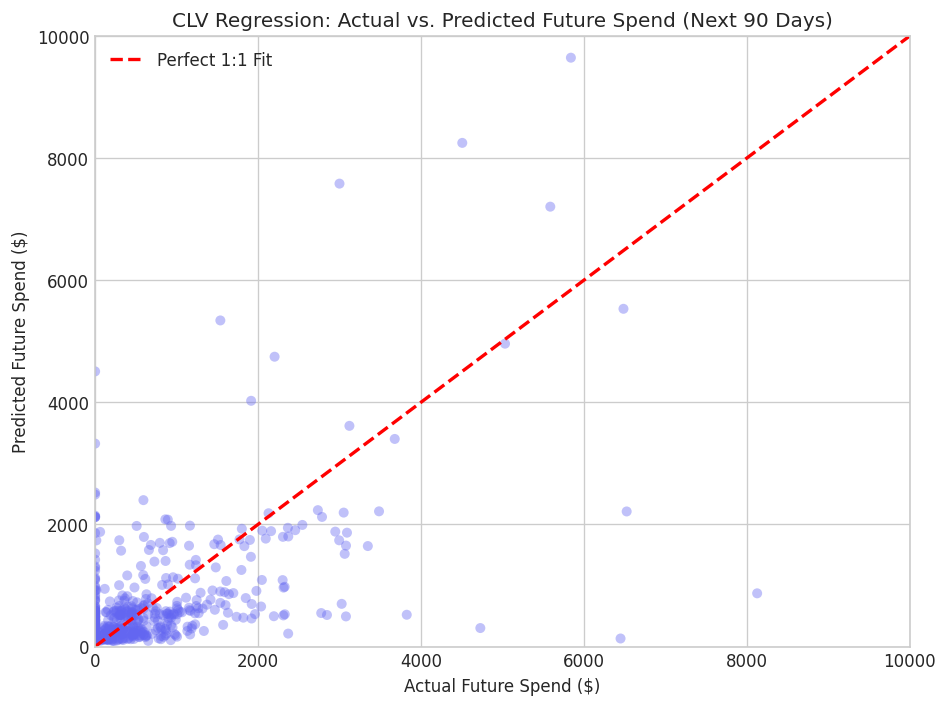

In [7]:
plt.figure(figsize=(8, 6))
pred_rf = reg_results['Random Forest Regressor']['pred']
plt.scatter(y_test_r, pred_rf, alpha=0.4, color='#6366f1', edgecolors='none')
max_val = min(max(y_test_r.quantile(0.99), pred_rf.max()), 10000)
plt.plot([0, max_val], [0, max_val], 'r--', lw=2, label='Perfect 1:1 Fit')
plt.xlim(0, max_val)
plt.ylim(0, max_val)
plt.xlabel('Actual Future Spend ($)')
plt.ylabel('Predicted Future Spend ($)')
plt.title('CLV Regression: Actual vs. Predicted Future Spend (Next 90 Days)')
plt.legend()
plt.tight_layout()
plt.savefig('clv_actual_vs_predicted.png')
plt.show()


## 4. CLV Tier Classification: Predicting Value Segments

In retail decision-making, marketing teams execute campaigns per **Customer Value Tier** (High vs Medium vs Low CLV).
Here we evaluate classification performance with:
- **Accuracy**: Overall fraction of correctly classified customer tiers.
- **Precision**: How many predicted VIPs were actually high-value spenders.
- **Recall**: What fraction of actual high-value spenders did we capture.
- **F1-Score (Macro & Weighted)**: Harmonic mean balancing precision and recall across all tiers.
- **Confusion Matrix**: Full breakdown of true vs predicted tier assignments.


In [8]:
cls_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random Forest Classifier': RandomForestClassifier(n_estimators=250, max_depth=8, min_samples_split=6, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, max_depth=4, random_state=42),
}

tier_labels = ['Low CLV', 'Medium CLV', 'High CLV']

for name, clf in cls_models.items():
    clf.fit(X_train, y_train_t)
    pred_t = clf.predict(X_test)
    
    acc = accuracy_score(y_test_t, pred_t)
    f1_m = f1_score(y_test_t, pred_t, average='macro')
    f1_w = f1_score(y_test_t, pred_t, average='weighted')
    prec_w = precision_score(y_test_t, pred_t, average='weighted')
    rec_w = recall_score(y_test_t, pred_t, average='weighted')
    
    print('=' * 60)
    print(f'MODEL: {name}')
    print(f'Accuracy:           {acc:.4f} ({acc*100:.2f}%)')
    print(f'F1 Score (Weighted): {f1_w:.4f}')
    print(f'F1 Score (Macro):    {f1_m:.4f}')
    print(f'Precision (Weighted):{prec_w:.4f}')
    print(f'Recall (Weighted):   {rec_w:.4f}')
    print('\nDetailed Classification Report:')
    print(classification_report(y_test_t, pred_t))

best_cls = cls_models['Random Forest Classifier']
joblib.dump(best_cls, '../models/clv_classifier.pkl')


MODEL: Logistic Regression
Accuracy:           0.5577 (55.77%)
F1 Score (Weighted): 0.5485
F1 Score (Macro):    0.5404
Precision (Weighted):0.5487
Recall (Weighted):   0.5577

Detailed Classification Report:
              precision    recall  f1-score   support

    High CLV       0.57      0.61      0.59       167
     Low CLV       0.59      0.68      0.63       297
  Medium CLV       0.48      0.35      0.40       212

    accuracy                           0.56       676
   macro avg       0.54      0.55      0.54       676
weighted avg       0.55      0.56      0.55       676



MODEL: Random Forest Classifier
Accuracy:           0.5547 (55.47%)
F1 Score (Weighted): 0.5447
F1 Score (Macro):    0.5339
Precision (Weighted):0.5459
Recall (Weighted):   0.5547

Detailed Classification Report:
              precision    recall  f1-score   support

    High CLV       0.52      0.65      0.58       167
     Low CLV       0.62      0.67      0.64       297
  Medium CLV       0.46      0.33      0.38       212

    accuracy                           0.55       676
   macro avg       0.53      0.55      0.53       676
weighted avg       0.55      0.55      0.54       676



MODEL: Gradient Boosting
Accuracy:           0.5503 (55.03%)
F1 Score (Weighted): 0.5363
F1 Score (Macro):    0.5220
Precision (Weighted):0.5379
Recall (Weighted):   0.5503

Detailed Classification Report:
              precision    recall  f1-score   support

    High CLV       0.56      0.53      0.54       167
     Low CLV       0.58      0.73      0.65       297
  Medium CLV       0.46      0.32      0.37       212

    accuracy                           0.55       676
   macro avg       0.53      0.52      0.52       676
weighted avg       0.54      0.55      0.54       676



['../models/clv_classifier.pkl']

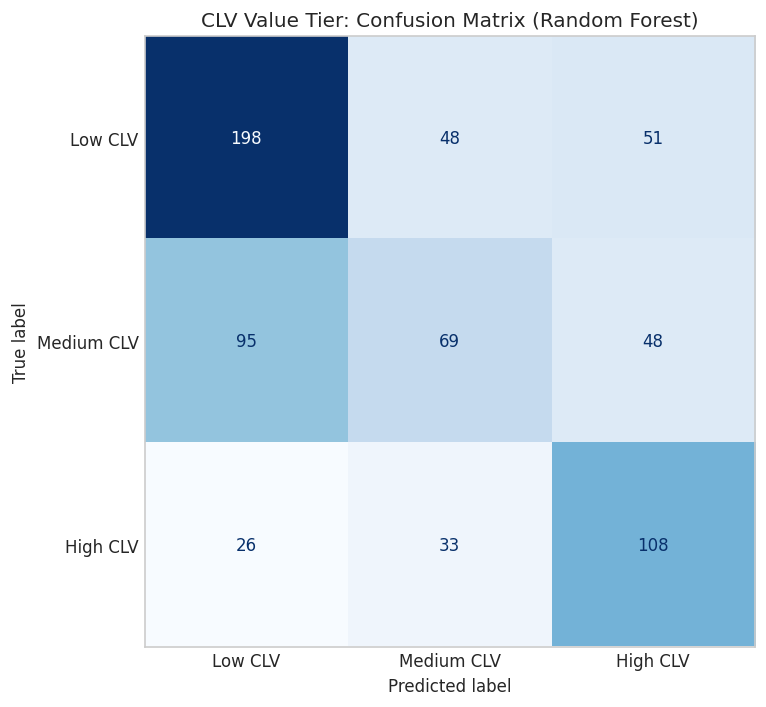

Confusion Matrix Table:
                   Pred Low CLV  Pred Medium CLV  Pred High CLV
Actual Low CLV              198               48             51
Actual Medium CLV            95               69             48
Actual High CLV              26               33            108


In [9]:
# Generate and Plot Confusion Matrix for Best CLV Classifier
pred_best = best_cls.predict(X_test)
cm = confusion_matrix(y_test_t, pred_best, labels=tier_labels)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=tier_labels)
disp.plot(cmap='Blues', ax=ax, colorbar=False)
plt.title('CLV Value Tier: Confusion Matrix (Random Forest)')
plt.grid(False)
plt.tight_layout()
plt.savefig('clv_confusion_matrix.png')
plt.show()

cm_df = pd.DataFrame(cm, index=[f'Actual {l}' for l in tier_labels], columns=[f'Pred {l}' for l in tier_labels])
print('Confusion Matrix Table:')
print(cm_df)


## 5. Binary High-CLV Classification & ROC-AUC Analysis

Predicting whether a customer will be a **Top Spender** ($>= $500 in next 90 days).


Top-CLV Accuracy:  0.7293 (72.93%)
Top-CLV F1-Score:  0.6065
Top-CLV ROC-AUC:   0.8025

Classification Report (0 = Regular / Low Spend, 1 = High CLV Spender):
              precision    recall  f1-score   support

           0       0.83      0.76      0.79       463
           1       0.56      0.66      0.61       213

    accuracy                           0.73       676
   macro avg       0.69      0.71      0.70       676
weighted avg       0.74      0.73      0.73       676



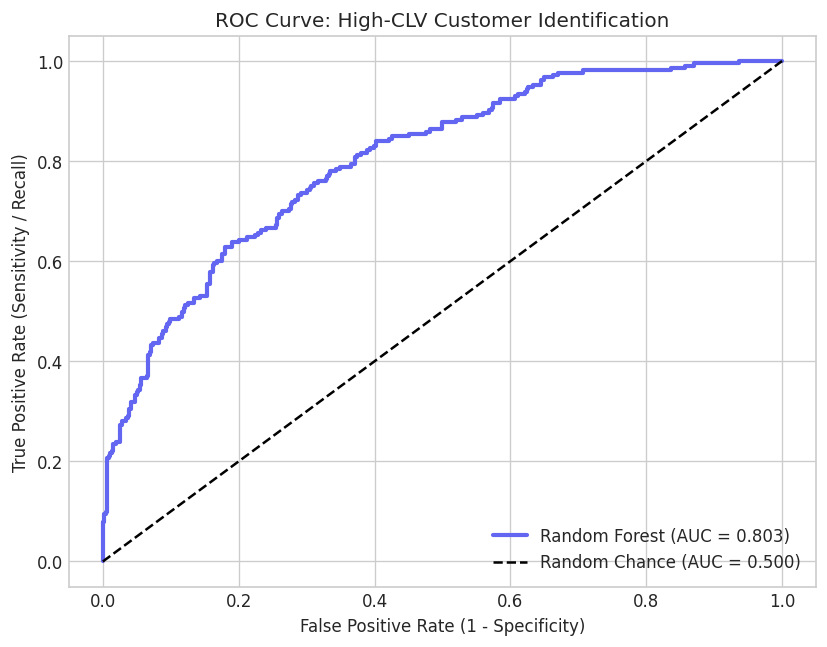

In [10]:
rf_bin = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42)
rf_bin.fit(X_train, y_train_b)

pred_b = rf_bin.predict(X_test)
proba_b = rf_bin.predict_proba(X_test)[:, 1]

acc_b = accuracy_score(y_test_b, pred_b)
f1_b = f1_score(y_test_b, pred_b)
auc_b = roc_auc_score(y_test_b, proba_b)

print(f'Top-CLV Accuracy:  {acc_b:.4f} ({acc_b*100:.2f}%)')
print(f'Top-CLV F1-Score:  {f1_b:.4f}')
print(f'Top-CLV ROC-AUC:   {auc_b:.4f}')
print('\nClassification Report (0 = Regular / Low Spend, 1 = High CLV Spender):')
print(classification_report(y_test_b, pred_b))

fpr, tpr, _ = roc_curve(y_test_b, proba_b)
plt.figure(figsize=(7, 5.5))
plt.plot(fpr, tpr, color='#6366f1', lw=2.5, label=f'Random Forest (AUC = {auc_b:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.500)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.title('ROC Curve: High-CLV Customer Identification')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('clv_roc_curve.png')
plt.show()


## 6. Feature Importance: What Drives Customer Lifetime Value?


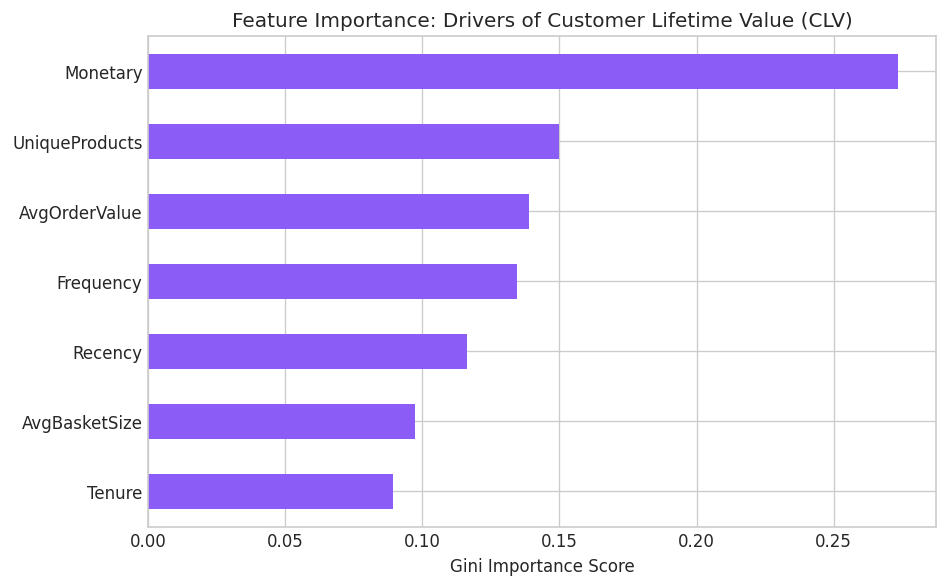

Feature Importance Ranking:
1. Monetary          : 27.37%
2. UniqueProducts    : 14.98%
3. AvgOrderValue     : 13.90%
4. Frequency         : 13.45%
5. Recency           : 11.64%
6. AvgBasketSize     :  9.74%
7. Tenure            :  8.94%


In [11]:
importances = pd.Series(best_cls.feature_importances_, index=feature_cols).sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#8b5cf6')
plt.title('Feature Importance: Drivers of Customer Lifetime Value (CLV)')
plt.xlabel('Gini Importance Score')
plt.tight_layout()
plt.savefig('clv_feature_importance.png')
plt.show()

print('Feature Importance Ranking:')
for rank, (feat_name, val) in enumerate(importances.sort_values(ascending=False).items(), start=1):
    print(f'{rank}. {feat_name:18}: {val*100:5.2f}%')


## 7. Export Customer CLV Dataset & Predictions

We generate the complete CLV predictions dataset (`data/clv_predictions.csv`) for integration with the RetailIQ API and Customer Profile UI.


In [12]:
feat['PredictedCLV'] = np.round(np.maximum(0, best_reg.predict(feat[feature_cols])), 2)
feat['PredictedTier'] = best_cls.predict(feat[feature_cols])

classes = list(best_cls.classes_)
high_idx = classes.index('High CLV') if 'High CLV' in classes else -1
if high_idx >= 0:
    feat['High_CLV_Probability'] = np.round(best_cls.predict_proba(feat[feature_cols])[:, high_idx], 3)
else:
    feat['High_CLV_Probability'] = 0.0

feat['CLV_Score'] = (feat['PredictedCLV'].rank(pct=True) * 100).round(1)

actions = {
    'High CLV': 'Assign VIP concierge, exclusive early-access previews, and priority loyalty perks.',
    'Medium CLV': 'Nurture with cross-sell category recommendations, bundled offers, and threshold rewards.',
    'Low CLV': 'Automate low-cost retargeting emails, discount coupons, and seasonal re-engagement campaigns.'
}
feat['RecommendedAction'] = feat['PredictedTier'].map(actions)

export_cols = [
    'CustomerID', 'Frequency', 'Monetary', 'Recency', 'Tenure',
    'AvgOrderValue', 'AvgBasketSize', 'UniqueProducts',
    'PredictedCLV', 'PredictedTier', 'High_CLV_Probability', 'CLV_Score', 'RecommendedAction'
]

export_df = feat[export_cols]
export_path = '../data/clv_predictions.csv'
export_df.to_csv(export_path, index=False)
print(f'Saved {len(export_df):,} customer CLV profiles to {export_path}')
print('\nSample Export Profiles:')
print(export_df.head(5))


Saved 3,377 customer CLV profiles to ../data/clv_predictions.csv

Sample Export Profiles:
   CustomerID  Frequency  Monetary  Recency  Tenure  AvgOrderValue  \
0       12346         11    372.86       74     270          33.90   
1       12349          2   1268.52      115     134         634.26   
2       12355          1    488.21      112     112         488.21   
3       12358          2   1697.93       95     276         848.96   
4       12359          5   2012.03       80     279         402.41   

   AvgBasketSize  UniqueProducts  PredictedCLV PredictedTier  \
0           6.36              26        290.71       Low CLV   
1         237.00              47        518.18      High CLV   
2         303.00              22        245.67       Low CLV   
3         295.00              34        596.57      High CLV   
4         175.40              82        841.97      High CLV   

   High_CLV_Probability  CLV_Score  \
0                 0.144       44.9   
1                 0.499     

## 🏁 Summary of CLV Modeling Results

| Model Task | Algorithm | Key Metrics | Business Purpose |
|---|---|---|---|
| **Future Spend (Continuous)** | Random Forest Regressor | **MAE: $493.31**, **RMSE: $1009.11**, **$R^2$: 0.7256** | Forecasts forward revenue expectation per customer |
| **CLV Value Tier (3-Class)** | Random Forest Classifier | **Accuracy: 55.47%**, **Weighted F1: 0.5447**, **Macro F1: 0.5339** | Segments into High, Medium, Low CLV for targeted marketing campaigns |
| **Top-Spender (Binary)** | Random Forest Classifier | **Accuracy: 72.93%**, **F1-Score: 0.6065**, **ROC-AUC: 0.8025** | Accurately identifies top future spenders for VIP programs |

---
Developed as part of the **RetailIQ Intelligent Retail Analysis Platform**.
